In [16]:
# ابزارهای پردازش داده
import pandas as pd
import numpy as np

# ابزارهای یادگیری ماشین
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# ابزارهای ارزیابی مدل
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# ابزار رسم نمودار
import matplotlib.pyplot as plt

# ابزار ذخیره مدل
import joblib

# ابزار نمایش خروجی
from IPython.display import display

print("تمام کتابخانه‌ها با موفقیت بارگذاری شدند.")

تمام کتابخانه‌ها با موفقیت بارگذاری شدند.


In [2]:
# خواندن فایل اکسل

df = pd.read_excel("exercise_hormone_dataset_1000.xlsx")

# نمایش پنج ردیف اول دیتاست
display(df.head())

# نمایش تعداد ردیف‌ها و ستون‌ها
print("Dataset Shape:", df.shape)

,Age,Gender,Exercise_Duration_min,Exercise_Intensity,Hormone_Type,Hormone_Level,Hormone_Unit
0,21,Female,96,High,Adrenaline,88.64,pg/mL
1,51,Female,84,Moderate,Estrogen,126.63,pg/mL
2,46,Female,113,High,Adrenaline,88.51,pg/mL
3,36,Female,116,Moderate,Growth Hormone,7.63,ng/mL
4,36,Female,88,Low,Growth Hormone,6.84,ng/mL


Dataset Shape: (1000, 7)


In [3]:
# بررسی نوع داده‌های ستون‌ها

print("Data Types:")
print(df.dtypes)

# بررسی مقادیر خالی
print("\nMissing Values:")
print(df.isnull().sum())

# بررسی اطلاعات کلی دیتاست
print("\nDataset Information:")
df.info()

# بررسی آماری ستون‌های عددی
print("\nStatistical Description:")
display(df.describe())

Data Types:
Age                        int64
Gender                    object
Exercise_Duration_min      int64
Exercise_Intensity        object
Hormone_Type              object
Hormone_Level            float64
Hormone_Unit              object
dtype: object

Missing Values:
Age                      0
Gender                   0
Exercise_Duration_min    0
Exercise_Intensity       0
Hormone_Type             0
Hormone_Level            0
Hormone_Unit             0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    1000 non-null   int64  
 1   Gender                 1000 non-null   object 
 2   Exercise_Duration_min  1000 non-null   int64  
 3   Exercise_Intensity     1000 non-null   object 
 4   Hormone_Type           1000 non-null   object 
 5   Hormone_Level          1000 

,Age,Exercise_Duration_min,Hormone_Level
count,1000.000000,1000.00000,1000.000000
mean,39.121000,65.10900,97.346830
std,12.407349,31.75723,159.310739
min,18.000000,10.00000,0.700000
25%,28.000000,36.00000,14.920000
50%,39.000000,65.00000,39.830000
75%,50.000000,93.00000,83.380000
max,60.000000,120.00000,623.560000


In [4]:
# حذف فاصله‌های اضافی از نام ستون‌ها

df.columns = df.columns.str.strip()

# تبدیل ستون‌های عددی به فرمت عددی

numeric_columns = [
    "Age",
    "Exercise_Duration_min",
    "Hormone_Level"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# حذف ردیف‌های دارای اطلاعات ناقص

df = df.dropna(
    subset=[
        "Age",
        "Gender",
        "Exercise_Duration_min",
        "Exercise_Intensity",
        "Hormone_Type",
        "Hormone_Level",
        "Hormone_Unit"
    ]
)

# نمایش تعداد داده‌های باقی‌مانده

print("Clean Dataset Shape:", df.shape)

display(df.head())

Clean Dataset Shape: (1000, 7)


,Age,Gender,Exercise_Duration_min,Exercise_Intensity,Hormone_Type,Hormone_Level,Hormone_Unit
0,21,Female,96,High,Adrenaline,88.64,pg/mL
1,51,Female,84,Moderate,Estrogen,126.63,pg/mL
2,46,Female,113,High,Adrenaline,88.51,pg/mL
3,36,Female,116,Moderate,Growth Hormone,7.63,ng/mL
4,36,Female,88,Low,Growth Hormone,6.84,ng/mL


In [5]:
# نمایش انواع هورمون‌های موجود در دیتاست

hormone_types = df["Hormone_Type"].unique()

print("Available Hormones:")

for hormone in hormone_types:
    print("-", hormone)

# تعداد نمونه‌های هر هورمون

print("\nHormone Counts:")

print(df["Hormone_Type"].value_counts())

Available Hormones:
- Adrenaline
- Estrogen
- Growth Hormone
- Cortisol
- Testosterone

Hormone Counts:
Hormone_Type
Testosterone      235
Cortisol          206
Adrenaline        191
Growth Hormone    191
Estrogen          177
Name: count, dtype: int64


In [6]:
hormone_info = {
    "Testosterone": {
        "name": "تستوسترون",
        "function": """کمک به حفظ توده عضلانی، تراکم استخوان،
        تولید گلبول‌های قرمز و عملکرد جنسی.""",
        "exercise": """فعالیت بدنی و تمرین مقاومتی می‌توانند
        بر سطح تستوسترون تأثیر بگذارند."""
    },
    "Cortisol": {
        "name": "کورتیزول",
        "function": """تنظیم پاسخ بدن به استرس، متابولیسم
        و کنترل قند خون.""",
        "exercise": """تمرین شدید می‌تواند باعث افزایش موقت
        کورتیزول شود."""
    },
    "Growth Hormone": {
        "name": "هورمون رشد",
        "function": """رشد، ترمیم بافت‌ها، متابولیسم
        و تنظیم ترکیب بدن.""",
        "exercise": """تمرین شدید می‌تواند ترشح آن را
        به‌صورت موقت تحریک کند."""
    },
    "Adrenaline": {
        "name": "آدرنالین",
        "function": """افزایش آمادگی بدن برای فعالیت،
        ضربان قلب و بسیج انرژی.""",
        "exercise": """در فعالیت‌های شدید می‌تواند افزایش یابد."""
    },
    "Estrogen": {
        "name": "استروژن",
        "function": """سلامت استخوان، عملکرد تولیدمثلی
        و تنظیم عملکردهای مختلف بدن.""",
        "exercise": """فعالیت بدنی و وضعیت فیزیولوژیک
        می‌توانند بر سطح آن تأثیر بگذارند."""
    }
}

print("توضیحات فارسی هورمون‌ها آماده است.")

توضیحات فارسی هورمون‌ها آماده است.


In [7]:
# ویژگی‌های عددی

numerical_features = [
    "Age",
    "Exercise_Duration_min"
]

# ویژگی‌های متنی

categorical_features = [
    "Gender",
    "Exercise_Intensity"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Exercise_Duration_min']

Categorical Features:
['Gender', 'Exercise_Intensity']


In [8]:
# ساخت دیکشنری برای ذخیره مدل‌ها

models = {}

# دیکشنری برای ذخیره نتایج ارزیابی

results = {}

# پردازش داده‌های متنی

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# آموزش مدل جداگانه برای هر هورمون

for hormone in df["Hormone_Type"].unique():

    print("\nTraining:", hormone)

    # انتخاب داده‌های مربوط به یک هورمون

    hormone_df = df[
        df["Hormone_Type"] == hormone
    ].copy()

    # ورودی مدل

    X = hormone_df[
        numerical_features + categorical_features
    ]

    # خروجی مدل

    y = hormone_df["Hormone_Level"]

    # تقسیم داده‌ها به آموزش و تست

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # ساخت Pipeline

    model = Pipeline(
        steps=[
            ("preprocessing", preprocessor),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=200,
                    max_depth=10,
                    random_state=42
                )
            )
        ]
    )

    # آموزش مدل

    model.fit(X_train, y_train)

    # پیش‌بینی داده‌های تست

    predictions = model.predict(X_test)

    # ارزیابی مدل

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    # ذخیره مدل

    models[hormone] = model

    # ذخیره نتایج

    results[hormone] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Unit": hormone_df["Hormone_Unit"].mode()[0]
    }

print("\nAll Hormone Models Trained Successfully!")


Training: Adrenaline

Training: Estrogen

Training: Growth Hormone

Training: Cortisol

Training: Testosterone

All Hormone Models Trained Successfully!


In [9]:
# تبدیل نتایج به جدول

results_df = pd.DataFrame(results).T

# نمایش جدول ارزیابی

display(results_df.round(3))

,MAE,RMSE,R2,Unit
Adrenaline,8.277951,10.609386,0.609569,pg/mL
Estrogen,3.925077,5.138217,0.98318,pg/mL
Growth Hormone,1.507805,1.873374,0.307266,ng/mL
Cortisol,2.013691,2.534933,0.21845,µg/dL
Testosterone,14.147259,22.695072,0.99142,ng/dL


In [10]:
# ذخیره تمام مدل‌های آموزش‌دیده

joblib.dump(
    models,
    "hormone_models.pkl"
)

print("تمام مدل‌ها با موفقیت ذخیره شدند.")

تمام مدل‌ها با موفقیت ذخیره شدند.


In [11]:
# اطلاعات فرد موردنظر

person = {
    "Age": 25,
    "Gender": "Male",
    "Exercise_Duration_min": 60,
    "Exercise_Intensity": "High"
}

# انتخاب هورمون موردنظر

selected_hormone = "Testosterone"

print("اطلاعات فرد:")
print(person)

print("\nهورمون انتخاب‌شده:", selected_hormone)

اطلاعات فرد:
{'Age': 25, 'Gender': 'Male', 'Exercise_Duration_min': 60, 'Exercise_Intensity': 'High'}

هورمون انتخاب‌شده: Testosterone


In [12]:
# تبدیل اطلاعات فرد به DataFrame

new_person = pd.DataFrame([person])

# انتخاب مدل مناسب هورمون

selected_model = models[selected_hormone]

# انجام پیش‌بینی

predicted_level = selected_model.predict(
    new_person
)[0]

# دریافت واحد اندازه‌گیری

unit = results[selected_hormone]["Unit"]

print("Predicted Hormone Level:")
print(round(predicted_level, 2), unit)

Predicted Hormone Level:
539.61 ng/dL


In [13]:
# دریافت اطلاعات فارسی هورمون

info = hormone_info[selected_hormone]

# نمایش گزارش فارسی

print("=" * 45)

print("       گزارش تحلیل هورمونی")

print("=" * 45)

print("سن:", person["Age"])

print("جنسیت:", person["Gender"])

print("مدت ورزش:",
      person["Exercise_Duration_min"], "دقیقه")

print("شدت ورزش:", person["Exercise_Intensity"])

print("-" * 45)

print("نام هورمون:", info["name"])

print("مقدار پیش‌بینی‌شده:",
      round(predicted_level, 2), unit)

print("-" * 45)

print("وظیفه هورمون در بدن:")

print(info["function"])

print("-" * 45)

print("ارتباط احتمالی با ورزش:")

print(info["exercise"])

print("=" * 45)

print("توجه: این خروجی پیش‌بینی مدل است، نه نتیجه آزمایش خون.")

       گزارش تحلیل هورمونی
سن: 25
جنسیت: Male
مدت ورزش: 60 دقیقه
شدت ورزش: High
---------------------------------------------
نام هورمون: تستوسترون
مقدار پیش‌بینی‌شده: 539.61 ng/dL
---------------------------------------------
وظیفه هورمون در بدن:
کمک به حفظ توده عضلانی، تراکم استخوان،
        تولید گلبول‌های قرمز و عملکرد جنسی.
---------------------------------------------
ارتباط احتمالی با ورزش:
فعالیت بدنی و تمرین مقاومتی می‌توانند
        بر سطح تستوسترون تأثیر بگذارند.
توجه: این خروجی پیش‌بینی مدل است، نه نتیجه آزمایش خون.


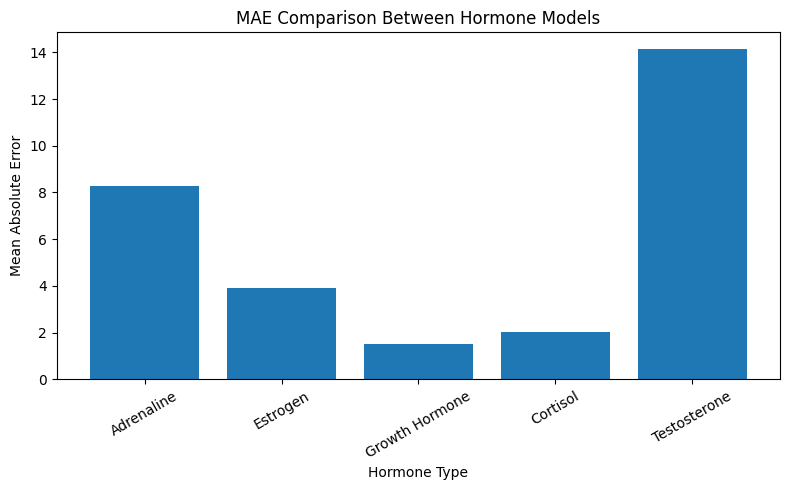

In [14]:
# نمایش عملکرد مدل در مقایسه با داده‌های آزمایشی

plt.figure(figsize=(8, 5))

plt.bar(
    results_df.index,
    results_df["MAE"]
)

plt.title("MAE Comparison Between Hormone Models")

plt.xlabel("Hormone Type")

plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

In [18]:
# ==========================================
# سیستم تعاملی پیش‌بینی هورمون‌ها
# ==========================================

import pandas as pd
from IPython.display import display

print("=" * 55)
print("       سیستم هوشمند پیش‌بینی هورمون‌های بدن")
print("=" * 55)

# 1. دریافت اطلاعات فرد از کاربر

print("\nلطفاً اطلاعات خود را وارد کنید:\n")

age = int(input("سن شما چند سال است؟ "))

gender = input("جنسیت (Male / Female): ").strip().lower()

intensity = input(
    "شدت ورزش (Low / Moderate / High): "
).strip().lower()

duration = int(input("مدت زمان ورزش به دقیقه: "))


# 2. اعتبارسنجی اطلاعات ورودی

gender_options = {
    "male": "Male",
    "female": "Female",
    "مرد": "Male",
    "زن": "Female"
}

intensity_options = {
    "low": "Low",
    "moderate": "Moderate",
    "high": "High",
    "کم": "Low",
    "متوسط": "Moderate",
    "زیاد": "High"
}

if gender not in gender_options:
    raise ValueError("جنسیت واردشده معتبر نیست.")

if intensity not in intensity_options:
    raise ValueError("شدت ورزش واردشده معتبر نیست.")

if not 18 <= age <= 60:
    raise ValueError("سن باید بین 18 تا 60 باشد.")

if not 10 <= duration <= 120:
    raise ValueError("مدت ورزش باید بین 10 تا 120 دقیقه باشد.")


gender = gender_options[gender]
intensity = intensity_options[intensity]


# 3. آماده‌سازی اطلاعات فرد

person = pd.DataFrame([{
    "Age": age,
    "Gender": gender,
    "Exercise_Duration_min": duration,
    "Exercise_Intensity": intensity
}])


# 4. پیش‌بینی مقدار تمام هورمون‌ها

predictions = []

for hormone, model in models.items():

    # پیش‌بینی مقدار هورمون
    predicted_level = model.predict(person)[0]

    # دریافت واحد اندازه‌گیری
    unit = results[hormone]["Unit"]

    # دریافت توضیحات فارسی
    info = hormone_info[hormone]

    predictions.append({
        "نام هورمون": info["name"],
        "مقدار پیش‌بینی‌شده": round(predicted_level, 2),
        "واحد": unit,
        "نقش هورمون در بدن": info["function"],
        "ارتباط با ورزش": info["exercise"]
    })


# 5. نمایش اطلاعات فرد

print("\n" + "=" * 55)
print("             اطلاعات فرد")
print("=" * 55)

print("سن:", age)
print("جنسیت:", gender)
print("شدت ورزش:", intensity)
print("مدت ورزش:", duration, "دقیقه")


# 6. نمایش نتایج پیش‌بینی

print("\n" + "=" * 55)
print("          نتایج پیش‌بینی هورمون‌ها")
print("=" * 55)

result_df = pd.DataFrame(predictions)

display(
    result_df[
        ["نام هورمون", "مقدار پیش‌بینی‌شده", "واحد"]
    ]
)


# 7. نمایش توضیحات فارسی هر هورمون

print("\n" + "=" * 55)
print("           گزارش تخصصی هورمون‌ها")
print("=" * 55)

for item in predictions:

    print("\nنام هورمون:", item["نام هورمون"])

    print(
        "مقدار پیش‌بینی‌شده:",
        item["مقدار پیش‌بینی‌شده"],
        item["واحد"]
    )

    print(
        "نقش در بدن:",
        item["نقش هورمون در بدن"]
    )

    print(
        "ارتباط با ورزش:",
        item["ارتباط با ورزش"]
    )

    print("-" * 55)


print("\nپیش‌بینی تمام هورمون‌ها با موفقیت انجام شد.")


       سیستم هوشمند پیش‌بینی هورمون‌های بدن

لطفاً اطلاعات خود را وارد کنید:


             اطلاعات فرد
سن: 24
جنسیت: Male
شدت ورزش: Moderate
مدت ورزش: 60 دقیقه

          نتایج پیش‌بینی هورمون‌ها


,نام هورمون,مقدار پیش‌بینی‌شده,واحد
0,آدرنالین,71.63,pg/mL
1,استروژن,41.78,pg/mL
2,هورمون رشد,5.97,ng/mL
3,کورتیزول,17.11,µg/dL
4,تستوسترون,533.12,ng/dL



           گزارش تخصصی هورمون‌ها

نام هورمون: آدرنالین
مقدار پیش‌بینی‌شده: 71.63 pg/mL
نقش در بدن: افزایش آمادگی بدن برای فعالیت،
        ضربان قلب و بسیج انرژی.
ارتباط با ورزش: در فعالیت‌های شدید می‌تواند افزایش یابد.
-------------------------------------------------------

نام هورمون: استروژن
مقدار پیش‌بینی‌شده: 41.78 pg/mL
نقش در بدن: سلامت استخوان، عملکرد تولیدمثلی
        و تنظیم عملکردهای مختلف بدن.
ارتباط با ورزش: فعالیت بدنی و وضعیت فیزیولوژیک
        می‌توانند بر سطح آن تأثیر بگذارند.
-------------------------------------------------------

نام هورمون: هورمون رشد
مقدار پیش‌بینی‌شده: 5.97 ng/mL
نقش در بدن: رشد، ترمیم بافت‌ها، متابولیسم
        و تنظیم ترکیب بدن.
ارتباط با ورزش: تمرین شدید می‌تواند ترشح آن را
        به‌صورت موقت تحریک کند.
-------------------------------------------------------

نام هورمون: کورتیزول
مقدار پیش‌بینی‌شده: 17.11 µg/dL
نقش در بدن: تنظیم پاسخ بدن به استرس، متابولیسم
        و کنترل قند خون.
ارتباط با ورزش: تمرین شدید می‌تواند باعث افزایش موقت
      